# Feature Selection & Dimensionality Reduction: Visium HD (Segmented)

## Introduction

Having filtered technical artifacts and standardized sequencing depth via size-factor log-normalization, we now transition from low-level matrix preprocessing to high-level biological pattern discovery. Whole-transcriptome Visium HD arrays quantify over 18,000 genes across tens of thousands of single cells (33,709 cells in our curated CRC ROI). However, the vast majority of these features represent either uninformative, ubiquitously expressed housekeeping genes or low-count Poisson shot noise.

As introduced in [the slides from the SIB](../assets/sib-slides/06_intermediate_processing.pdf) and [its accompagnying note](../assets/notes/06-intermediate_processing.md), in this notebook, we implement **intermediate processing** across our segmented dataset:

1. **Feature Selection:** We evaluate feature variance to separate technical sampling noise from true biological overdispersion, selecting the top 1,000 Highly Variable Genes (HVGs). We contrast these cell-autonomous features with Spatially Variable Genes (SVGs), which explicitly account for spatial coordinates $(x, y)$.
2. **Linear Dimensionality Reduction:** We perform Principal Component Analysis (PCA) on top HVGs, evaluating scree variance plateaus and projecting top principal components onto histological coordinates.
3. **Spatially-Aware Dimensionality Reduction (BANKSY):** We construct spatial neighborhood graphs to augment each cell's transcriptome with the mean expression of its physical neighbors, generating a joint spatio-molecular embedding that resists single-cell dropout noise and sharpens cribriform tumor margins.
4. **Non-Linear Manifold Projection (UMAP):** We contrast standard non-spatial PCA with BANKSY spatio-molecular PCA in two-dimensional UMAP space.

## Learning objectives

* Model feature-level mean-variance relationships using Poisson dispersion models (`scran::modelGeneVarByPoisson`) to select top HVGs.
* Contrast the biological assumptions and computational trade-offs of HVGs versus SVGs across dense single-cell spatial arrays.
* Compute and interpret standard PCA loadings, linking orthogonal eigenvectors to canonical colorectal histological compartments (normal crypts, invasive cribriform adenocarcinoma, desmoplastic stroma).
* Implement the BANKSY spatio-molecular framework (`Banksy::computeBanksy`, `Banksy::runBanksyPCA`), tuning the neighborhood mixing parameter λ.
* Project linear and non-linear latent representations back onto physical histological coordinates (`Voyager::spatialReducedDim`).

## Environment setup

### Loading libraries

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial & Bioconductor containers
  library(SpatialFeatureExperiment)
  library(Voyager)
  library(alabaster.sfe)

  # Single-cell statistics & feature modeling
  library(scran)
  library(scater)

  # Spatially-aware dimensionality reduction & spatial stats
  library(Banksy)

  # Visualization, palettes & layouts
  library(ggplot2)
  library(patchwork)
  library(pals)
}))

# Enforce global reproducibility for stochastic algorithms (PCA, UMAP, sampling)
set.seed(42)  # Works if the notebook is executed strictly once from top to bottom

### Restoring the normalized Visium HD dataset

We restore the normalized `SpatialFeatureExperiment` (`sfe`) object generated in [notebook 07](./07-normalization_VisiumHD_segmented.ipynb).

In [2]:
# Define path to the normalized Visium HD segmented object from notebook 07
sfe_path <- "output/sfe_visiumhd_segmented_normalized"

# Restore the SFE object using alabaster serialization
sfe <- readObject(sfe_path)

# Verify container integrity, assays, and spatial geometries
sfe

>>> Reading SpatialExperiment

>>> Reading colgeometries



class: SpatialFeatureExperiment 
dim: 18049 33709 
metadata(1): Samples
assays(2): counts logcounts
rownames(18049): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(4): ID Symbol Type subsets_Mito
colnames(33709): 80404 80411 ... 189331 189341
colData names(36): Sample Barcode ... sizeFactor_smooth sf_ratio
reducedDimNames(1): PCA_artifacts
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: 

This object contains 33,709 post-QC _segmented_ single cells and 18,049 expressed genes across two primary assay matrices: raw `counts` and size-factor normalized `logcounts`.

## Feature selection

### Highly Variable Genes (HVGs)

In unconstrained single-cell transcriptomics, feature selection isolates genes displaying variation substantially greater than expected from technical Poisson sampling alone. 

Using `scran::modelGeneVarByPoisson()`, we decompose the total observed variance $\sigma^2_{\text{total}, g}$ of each gene $g$ in `logcounts` into a fitted technical variance component $\sigma^2_{\text{tech}, g}$ (modeled under the assumption that non-biological noise follows Poisson count statistics) and a residual biological variance component:

$$
\sigma^2_{\text{bio}, g} = \sigma^2_{\text{total}, g} - \sigma^2_{\text{tech}, g}
$$

Genes exhibiting the highest biological variance ($\sigma^2_{\text{bio}, g} \gg 0$) represent lineage-defining transcription factors, structural markers, and oncogenic drivers that distinguish the primary cellular compartments within CRC tissue.

#### Modeling the Mean-Variance Relationship

In [3]:
# Model mean-variance relationship under a Poisson technical noise assumption
gene_var <- modelGeneVarByPoisson(sfe, assay.type = "logcounts")

Warning message in .model_gene_var_by_poisson(assay(x, i = assay.type), ...):
"'modelGeneCV2ByPoisson' est obsolète.
Voir help("Deprecated")"
Warning message in fitTrendVar(fm, fv, ...):
"'fitTrendVar' est obsolète.
Utilisez plutôt ‘scrapper::fitVarianceTrend’.
Voir help("Deprecated")"
Warning message in combineBlocks(collected, method = method, equiweight = equiweight, :
"'combineBlocks' est obsolète.
Voir help("Deprecated")"


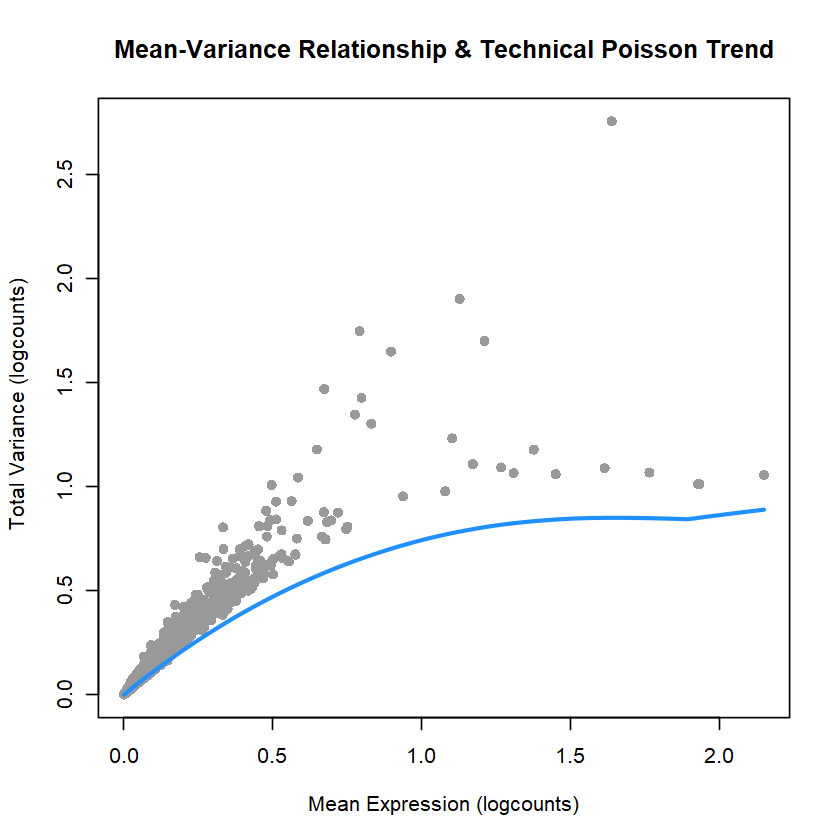

In [4]:
# Scatter plot: Total observed variance vs. mean logcounts for all 18,049 genes
plot(
  x = gene_var[["mean"]], 
  y = gene_var[["total"]], 
  pch = 16, 
  col = "gray60", 
  xlab = "Mean Expression (logcounts)", 
  ylab = "Total Variance (logcounts)", 
  main = "Mean-Variance Relationship & Technical Poisson Trend"
)

# Overlay fitted technical trend:
# scran stores the fitted Poisson noise model as a vectorized function in metadata(gene_var)[["trend"]].
# curve() evaluates this function over the x-axis range (mean expression) and overlays the blue line.
# Genes located along this line have zero excess biological variance (pure technical noise),
# whereas points rising vertically above the curve represent biologically variable features.
curve(
  metadata(gene_var)[["trend"]](x), 
  add = TRUE, 
  col = "dodgerblue", 
  lwd = 2.5
)

The fitted mean-variance curve exhibits the expected concave upward trajectory characteristic of log-transformed Poisson technical noise:

* **Low-expression baseline (mean < 0.5):** Total variance is constrained by detection limits and dropout sparsity, closely tracking the blue Poisson technical baseline ($\sigma^2_{\text{bio}} \approx 0$). In this regime, observed fluctuations represent random sampling shot noise rather than cell-type heterogeneity.
* **Biological overdispersion (0.65 ≤ mean ≤ 2.15):** The technical Poisson baseline ($\sigma^2_{\text{tech}}$) gradually plateaus between 0.57 and 0.85. Above this threshold, true biological heterogeneity manifests as substantial vertical separation above the blue curve, with top candidate genes displaying severe biological overdispersion ($\sigma^2_{\text{bio}} > 1.0$).

#### Ranking Top Biological Drivers

To identify the genes driving the strongest vertical displacement above the Poisson baseline, we rank features by their excess biological variance ($\sigma^2_{\text{bio}}$) and inspect the top 10 candidates.

In [5]:
# Sort and extract top 10 biological drivers cleanly without mutating gene_var
gene_var |> 
  as.data.frame() |> 
  dplyr::slice_max(bio, n = 10)

,mean,total,tech,bio,p.value,FDR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
IGKC,1.6381687,2.756403,0.8502543,1.9061484,0,0
COL3A1,1.1273010,1.902910,0.7838954,1.1190149,0,0
IGHG1,0.7913821,1.747158,0.6511826,1.0959758,0,0
COL1A1,0.8972008,1.649126,0.7013289,0.9477968,0,0
VIM,1.2112031,1.700549,0.8052333,0.8953158,0,0
JCHAIN,0.6726765,1.469489,0.5854726,0.8840167,0,0
COL1A2,0.7978221,1.427818,0.6544744,0.7733435,0,0
SPARC,0.7755334,1.346592,0.6429845,0.7036079,0,0
CD74,0.8308440,1.302478,0.6707769,0.6317016,0,0


Remarkably, the highest biological variance in this tissue section is commanded by `IGKC` ($\sigma^2_\text{bio} = 1.906, \sigma^2_\text{total} = 2.756$), followed by fibrillar collagen `COL3A1` ($\sigma^2_{\text{bio}} = 1.119$) and `IGHG1` ($\sigma^2_{\text{bio}} = 1.096$). All top 10 candidates achieve extreme statistical significance (FDR = 0), demonstrating that the primary molecular variance across Patient P2 is driven by dense, spatially clustered immune and stromal compartments rather than baseline epithelial transcript fluctuations.

> In uncurated single-cell and spatial datasets, mitochondrial genes (such as `MT-CO1`, `MT-CO3`, or `MT-ATP6`) frequently appear as extreme vertical outliers with total variance exceeding 8–10 at high mean expression. This massive variance is driven primarily by technical and pathological artifacts: cells with compromised cell membranes or apoptotic blebs lose cytoplasmic mRNA while retaining mitochondria, creating artificial expression spikes.
> 
> Because our upstream two-tiered quality control ([notebook 04](./04-quality_control_VisiumHD_segmented.ipynb)) systematically purged cells with aberrant mitochondrial content using `SpotSweeper` local Z-scores and an 18% global ceiling, these artificial variance spikes were eliminated from our dataset. As a result, our maximum total variance tops out at ≈ 2.76, allowing authentic histological drivers (`IGKC`, `COL3A1`, `IGHG1`) to emerge at the top of the biological hierarchy. Nevertheless, as a standard precautionary safeguard, we explicitly verify and exclude any remaining mitochondrial features prior to selecting our final HVG set for dimensionality reduction.

#### Spatial Topographies of the Top 6 HVGs

As a standard precautionary safeguard, we exclude mitochondrial genes (`subsets_Mito`) before extracting the top 6 HVGs and projecting their normalized expression onto our segmented cell polygons.

In [6]:
# Filter out mitochondrial genes to prevent non-specific metabolic noise from dominating
is_mito <- rowData(sfe)[["subsets_Mito"]]
gene_var_filtered <- gene_var[!is_mito, ]

# Extract the top 6 empirical HVGs natively using scran::getTopHVGs (independent of table sorting)
top_hvg <- getTopHVGs(gene_var_filtered, n = 6)
top_hvg

Warning message in getTopHVGs(gene_var_filtered, n = 6):
"'getTopHVGs' est obsolète.
Utilisez plutôt ‘scrapper::chooseHighlyVariableGenes’.
Voir help("Deprecated")"


[1] "IGKC"   "COL3A1" "IGHG1"  "COL1A1" "VIM"    "JCHAIN"

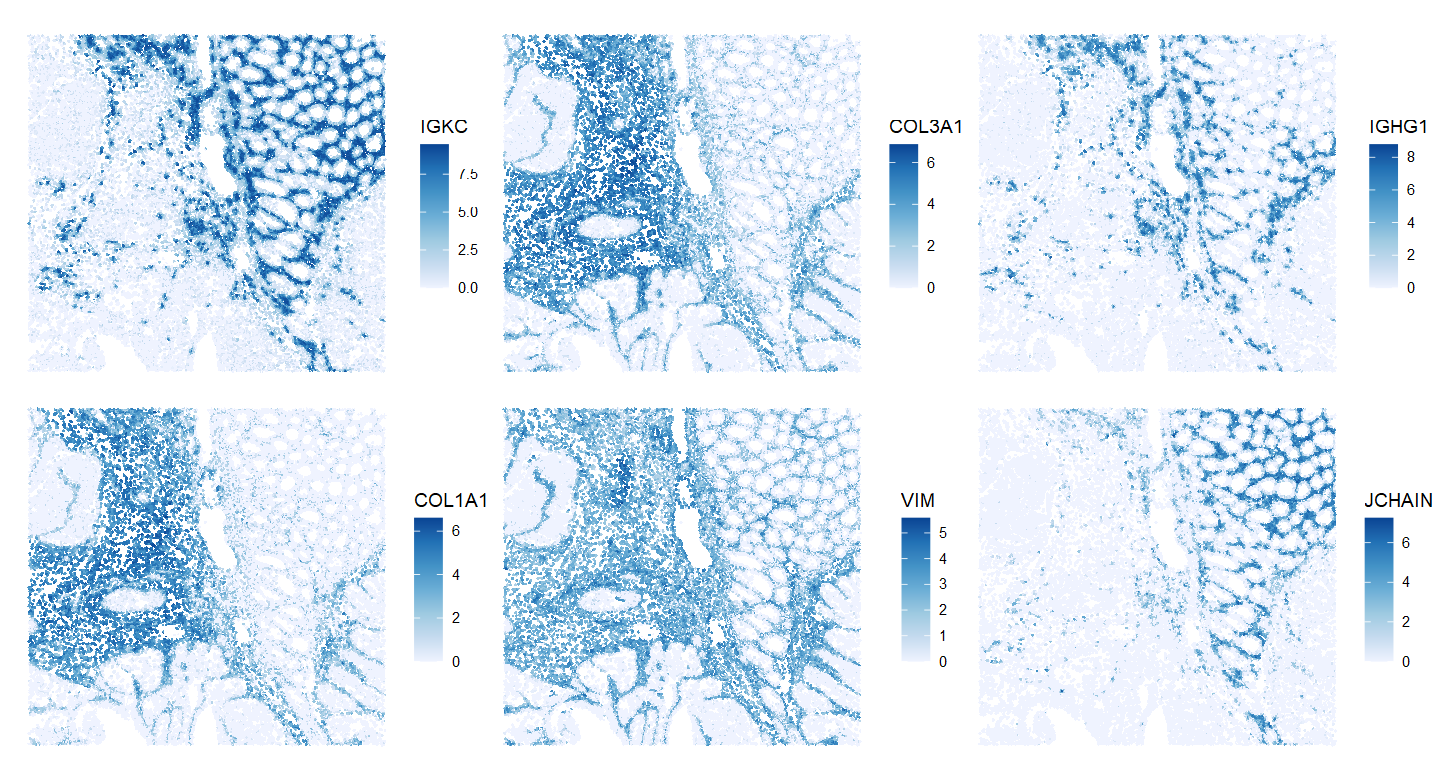

In [7]:
# Set canvas dimensions
options(repr.plot.width = 12, repr.plot.height = 6.5)

# Render spatial expression topographies across segmented cell polygons
plotSpatialFeature(
  sfe, 
  features = top_hvg, 
  colGeometryName = "cellSeg", 
  ncol = 3
)

The honeycomb pattern in the upper-right histological compartment reflects normal colonic mucosa. Signal is concentrated in the surrounding lamina propria, populated by **B-lineage immune leukocytes (plasma cells)**:

* **`JCHAIN`:** Strictly restricted to this mucosal compartment, where plasma cells synthesize dimeric IgA for epithelial transcytosis into the gut lumen. It is completely absent from the tumor bed.
* **`IGKC`:** Heavily labels these mucosal plasma cells, while also marking peritumoral immune infiltrates.

The left half captures invasive cribriform adenocarcinoma embedded within a reactive stroma:

* **`COL1A1` & `COL3A1`:** Display tightly coupled expression in cancer-associated fibroblasts (CAFs), forming dense fibrillar collagen bands that encapsulate malignant glandular nests. Both collagens are silent in the normal crypt mucosa.
* **`VIM` (Vimentin):** Broadly labels the mesenchymal compartment, including CAFs, microvascular endothelia, and invasive tumor cells undergoing epithelial–mesenchymal transition (EMT).

While `JCHAIN` defines baseline mucosal IgA immunity in normal crypts, **`IGHG1`** is concentrated along the central vertical boundary between normal mucosa and invasive tumor. This marks an _anti-tumor humoral response_ driven by IgG-secreting plasma cells responding to neoplastic neoantigens.

Large oval voids in the upper-left and lower-central regions represent submucosal arterioles and venules packed with anucleate erythrocytes. These transcript-sparse lumina appear as unexpressed negative spaces, sharply framed by endothelial `VIM` and perivascular collagens (`COL1A1`/`COL3A1`).

#### Selecting & Summarizing the Top 1,000 HVG Cohort

Downstream dimensionality reduction requires an optimal feature cohort (typically 1,000–2,000 genes) that balances transcriptional information against stochastic dropouts. 

We extract the top 1,000 _non-mitochondrial_ genes ranked by biological variance ($\sigma^2_{\text{bio}}$) and register this logical mask directly into `rowData(sfe)[["is_hvg"]]` for seamless indexing across all downstream PCA and graph computations.

In [8]:
# Select the top 1,000 non-mitochondrial HVGs natively with getTopHVGs
hvg_1000 <- getTopHVGs(gene_var_filtered, n = 1000)

# Register both the variance component and the HVG selection mask directly into rowData
rowData(sfe)[["bio"]] <- gene_var[["bio"]]
rowData(sfe)[["is_hvg"]] <- rownames(sfe) %in% hvg_1000

# Verify registration
table(Retained_HVG = rowData(sfe)[["is_hvg"]])

Warning message in getTopHVGs(gene_var_filtered, n = 1000):
"'getTopHVGs' est obsolète.
Utilisez plutôt ‘scrapper::chooseHighlyVariableGenes’.
Voir help("Deprecated")"


Retained_HVG
FALSE  TRUE 
17049  1000 

In [9]:
# Summarize biological variance directly across the selected HVGs in rowData
summary(rowData(sfe)[rowData(sfe)[["is_hvg"]], "bio"])

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.05369 0.06115 0.07653 0.10590 0.10578 1.90615 

In [10]:
# Extract the HVG subset directly from rowData as a clean data.frame
df_hvg_bio <- as.data.frame(rowData(sfe)[rowData(sfe)[["is_hvg"]], ])
df_hvg_bio[["gene"]] <- rownames(df_hvg_bio)

# Extract top 3 outliers WITH exact jittered coordinates
top_outliers <- df_hvg_bio[order(df_hvg_bio[["bio"]], decreasing = TRUE), ][1:3, ]

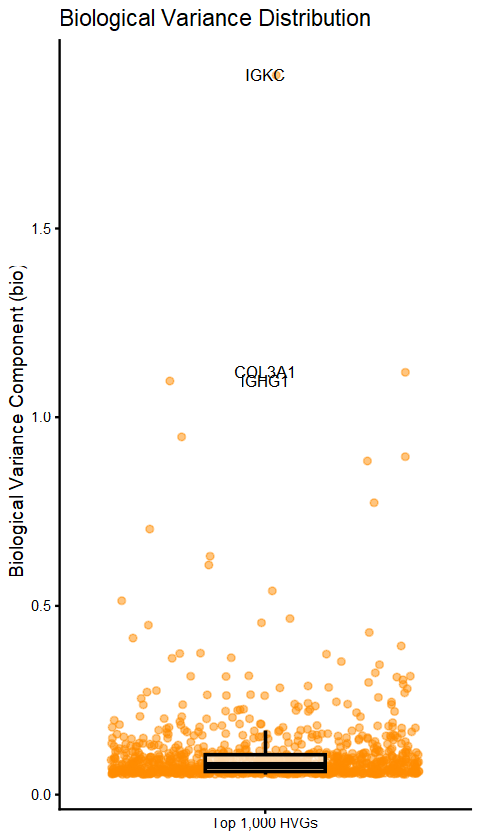

In [11]:
# Set canvas dimensions thinner for a single vertical boxplot
options(repr.plot.width = 4, repr.plot.height = 7)

# Plot boxplot with all 1,000 individual data points overlaid
p_bio_box <- ggplot(df_hvg_bio, aes(x = "Top 1,000 HVGs", y = bio)) +
  # Overlay all 1,000 jittered points
  geom_jitter(
    width = 0.45, 
    size = 1.5, 
    alpha = 0.5, 
    color = "darkorange"
  ) +
  # Overlay semi-transparent boxplot (outlier.shape = NA prevents double-plotting)
  geom_boxplot(
    width = 0.35, 
    fill = "white", 
    alpha = 0.65, 
    color = "black", 
    linewidth = .75, 
    outlier.shape = NA
  ) +
  # Label top 3 extreme drivers
  geom_text(
    data = top_outliers,
    aes(label = gene),
    size = 3.5,
  ) +
  theme_classic() +
  labs(
    title = "Biological Variance Distribution",
    x = NULL,
    y = "Biological Variance Component (bio)"
  )

p_bio_box

The dense cluster of points is tightly packed between the 1st quartile (0.0608) and 3rd quartile (0.1055) around a median of 0.0762, resting above the empirical selection floor of $\sigma^2_{\text{bio}} \ge 0.0533$. These features capture subtle localized metabolic states and microenvironmental signaling gradients.

Stretching high above the upper whisker are isolated lineage drivers, led by `IGKC` (1.9061), `COL3A1` (1.1190), and `IGHG1` (1.0960). These isolated points represent massive humoral immune and desmoplastic programs that define major histological compartments in Patient P2.

By capturing both the dense basal cohort and these top structural drivers, the 1,000-gene feature set provides a balanced foundation for downstream dimensionality reduction.

### Spatially Variable Genes (SVGs)

Because `scran::modelGeneVarByPoisson()` evaluates gene variance independently of tissue location, high molecular variance does not guarantee spatial organization. A gene in our 1,000-HVG cohort may rank highly either because it delineates a contiguous histological compartment or because it captures spatially scattered biological states (such as cell-cycle progression or transient metabolic activity).

**Spatially Variable Genes (SVGs)** resolve this ambiguity by explicitly integrating tissue coordinates $(x, y)$—either via spatial autocorrelation on neighborhood graphs (Moran's I) or distance-based Gaussian process kernels (`nnSVG`)—to identify features with non-random spatial patterning. To illustrate this contrast, we first sample six genes from our `hvg_1000` set at random and inspect their spatial distributions across the segmented cell polygons.

In [12]:
# Sample 6 random genes from the top 1,000 HVG set to assess spatial coherence variability
set.seed(42)
random_hvg <- sample(hvg_1000, size = 6)
random_hvg

[1] "SH3GLB1" "DAP"     "RNF149"  "SFRP4"   "FLNA"    "DAB2"

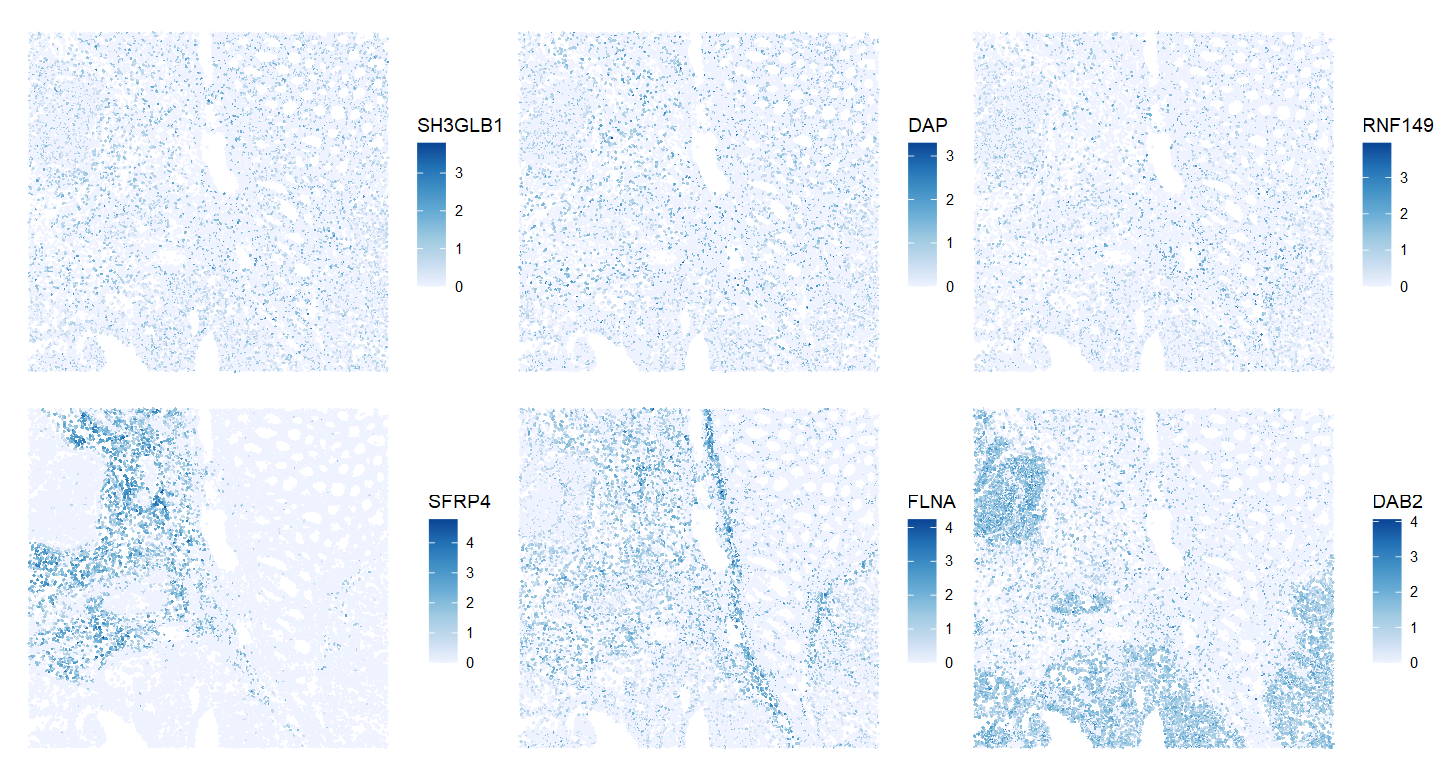

In [13]:
# Set canvas dimensions
options(repr.plot.width = 12, repr.plot.height = 6.5)

# Map their spatial expression across segmented cell polygons
plotSpatialFeature(
  sfe, 
  features = random_hvg, 
  colGeometryName = "cellSeg", 
  ncol = 3
)

The six randomly sampled HVGs split cleanly into two spatial regimes, proving that high molecular variance does not guarantee spatial organization:

* **Spatially diffuse HVGs (`SH3GLB1`, `DAP`, `RNF149`; top panels):** Exhibit uniform, punctate expression scattered across both tumor and normal mucosa without delineating any histological boundary.
* **Spatially cohesive HVGs / true SVGs (`SFRP4`, `FLNA`, `DAB2`; bottom panels):** Map sharply onto distinct tissue compartments—`SFRP4` is restricted to the left-side desmoplastic CAF stroma, `FLNA` traces the vertical smooth-muscle band of the muscularis mucosae alongside stromal vessels, and `DAB2` highlights dense submucosal and perivascular bands while sparing the upper-right crypts.

#### Graph-Based (Fast) Spatial Autocorrelation (Moran's I)

To quantify the visual contrast observed between diffuse (`SH3GLB1`, `DAP`, `RNF149`) and spatially cohesive (`SFRP4`, `FLNA`, `DAB2`) HVGs, we construct a $k$-nearest neighbor spatial graph ($k = 6$) over our 33,709 cell centroids and compute **Moran's I** via `Voyager::runMoransI()`.

Because `Voyager` computes exact analytical expectations gene-by-gene via `spdep` across all 33,709 nodes, running it across thousands of features incurs substantial serial loop overhead on single-core Windows sessions. Instead, we target our curated 10-gene benchmark panel—combining four canonical CRC compartment markers (`IGKC`, `COL3A1`, `PIGR`, `CEACAM5`) with our six randomly sampled HVGs—completing the calculation in seconds and storing the spatial autocorrelation scores directly in `rowData(sfe)`.

In [14]:
# Construct a k-NN spatial neighbor graph and register it in colGraph(sfe)
colGraph(sfe, "knn6") <- SpatialFeatureExperiment::findSpatialNeighbors(
  sfe, 
  method = "knearneigh", 
  k = 6, 
  zero.policy = TRUE
)

In [15]:
# Define the curated 10-gene benchmark panel (canonical markers + 6 random HVGs)
svg_benchmark_genes <- unique(c("IGKC", "COL3A1", "PIGR", "CEACAM5", random_hvg))

In [16]:
# Compute Moran's I across the benchmark panel
sfe <- Voyager::runMoransI(
  sfe, 
  features = svg_benchmark_genes, 
  colGraphName = "knn6"
)

In [17]:
# Inspect biological variance and Moran's I side-by-side
rowData(sfe)[svg_benchmark_genes, ] |> 
  as.data.frame() |> 
  dplyr::select(bio, dplyr::starts_with("moran_")) |> 
  dplyr::arrange(dplyr::desc(moran_sample01)) |> 
  signif(3)

,bio,moran_sample01
,<dbl>,<dbl>
IGKC,1.9100,0.8500
PIGR,0.5400,0.7760
COL3A1,1.1200,0.7540
CEACAM5,0.2380,0.6740
SFRP4,0.1370,0.5360
DAB2,0.1110,0.3850
FLNA,0.1970,0.1810
DAP,0.0537,0.0198
RNF149,0.0953,0.0185


`IGKC` leads both metrics ($\sigma^2_{\text{bio}} = 1.91$, Moran's I = 0.850), followed closely by normal crypt marker `PIGR` (0.776), desmoplastic collagen `COL3A1` (0.754), and adenocarcinoma marker `CEACAM5` (0.674). Notably, `SFRP4` and `DAB2` exhibit modest biological variance ($\sigma^2_{\text{bio}}$ = 0.137 and 0.111) yet achieve strong spatial autocorrelation (0.536 and 0.385) because they occupy cohesive stromal and submucosal patches.

In sharp contrast, `DAP` (0.0198), `RNF149` (0.0185), and `SH3GLB1` (0.0118) collapse to near-zero spatial autocorrelation, confirming quantitatively that their cell-to-cell variance is scattered uniformly across the tissue without anatomical clustering.

Despite having higher biological variance ($\sigma^2_{\text{bio}}$ = 0.197) than `SFRP4` or `DAB2`, `FLNA` scores noticeably lower on Moran's I (0.181). Because `FLNA` traces a thin, linear smooth-muscle band (the muscularis mucosae; see the very last spatial map figure) and narrow vessel walls, many of a cell's $k = 6$ nearest neighbors sit outside the thin line—diluting fixed-neighborhood autocorrelation. This exact limitation motivates multi-scale Gaussian process models (`nnSVG`), which adapt their spatial length scale ($l_g$) to each gene.

> **Technical Note on Column Naming (`moran_sample01`):** `Voyager::runMoransI()` automatically suffixes the output column with the object's internal `sample_id` (`sample01` by default). Had a custom identifier (such as `CRC_P2`) been assigned during earlier data ingestion, the resulting column would be named `moran_CRC_P2` accordingly.

#### Multi-Scale Gaussian Process Modeling (`nnSVG`)

To overcome fixed-neighborhood dilution without manually tuning $k$, [`nnSVG`](https://www.nature.com/articles/s41467-023-39748-z) ([Bioconductor vignette](https://bioconductor.org/packages/release/bioc/vignettes/nnSVG/html/nnSVG.html)) fits Nearest-Neighbor Gaussian Process (NNGP) models that estimate spatial variance proportions (`prop_sv`) alongside a gene-specific length scale ($l_g$). Optimizing $l_g$ per gene enables multi-scale pattern discovery—simultaneously resolving broad invasive tumor sheets spanning hundreds of microns ($l_g$ > 200 µm) and fine 15–30 µm niches such as microvascular capillaries, mucosal crypt stems, or thin `FLNA`-positive smooth-muscle bands ($l_g$ ≈ 20 µm).

Because fitting NNGP models across 33,709 cells is computationally intensive, we execute `nnSVG()` on our 10-gene benchmark subset (`sub`) for direct comparison against Moran's I, while keeping our full `sfe` object intact for downstream BANKSY dimensionality reduction.

> Unlike `Voyager::runMoransI()`, `nnSVG::nnSVG()` does not expose a `features` parameter and instead evaluates every row present in its input container. To keep our workflow unified, we execute `nnSVG()` on the 10-gene subset (`svg_benchmark_genes`).

In [18]:
# Subset the SFE object to the 10-gene benchmark panel
sub <- sfe[svg_benchmark_genes, ]

# Fit Nearest-Neighbor Gaussian Process models (takes ≈ 10 minutes)
set.seed(42)
sub <- nnSVG::nnSVG(sub)

Warning message in nnSVG::nnSVG(sub):
"Rows (genes) and/or columns (spots) containing all zero counts have been found. Please see examples in tutorial for code to filter out zeros and/or low-expressed genes to avoid errors."
Warning message in MulticoreParam(workers = n_threads):
"MulticoreParam() not supported on Windows, use SnowParam()"


For each tested gene, `nnSVG()` appends the fitted Nearest-Neighbor Gaussian Process (NNGP) model parameters—including spatial variance ($\sigma^2$; `sigma.sq`), non-spatial variance ($\tau^2$; `tau.sq`), and inverse length-scale ($\phi = 1/l_g$; `phi`)—alongside hypothesis-testing statistics directly into `rowData`.

In [19]:
names(rowData(sub))

[1] "ID"             "Symbol"         "Type"           "subsets_Mito"  
 [5] "bio"            "is_hvg"         "moran_sample01" "K_sample01"    
 [9] "sigma.sq"       "tau.sq"         "phi"            "loglik"        
[13] "runtime"        "mean"           "var"            "spcov"         
[17] "prop_sv"        "loglik_lm"      "LR_stat"        "rank"          
[21] "pval"           "padj"

From these outputs, we extract three primary summary metrics to compare against Moran's I:

* **`LR_stat` (Likelihood Ratio Statistic):** Measures the goodness-of-fit improvement of the spatially-aware NNGP model over a non-spatial null model. Higher values indicate stronger evidence for spatial structure.
* **`prop_sv` (Proportion of Spatial Variance):** Defined as $\frac{\sigma^2}{\sigma^2 + \tau^2}$, quantifying the exact fraction (0 to 1) of a gene's total variance explained by spatial location rather than cell-to-cell non-spatial noise ($\tau^2$).
* **`padj` (Adjusted P-value):** Benjamini–Hochberg false discovery rate derived from the $\chi^2_2$ likelihood ratio test of `LR_stat`.

We initialize matching columns in `rowData(sfe)` (`NA` for untested genes), and transfer `LR_stat`, `prop_sv`, and `padj` back into our primary `sfe` object—allowing a direct, side-by-side comparison of both spatial statistics from a single container.

In [20]:
# Initialize columns in rowData(sfe) and transfer the nnSVG results back
nnsvg_cols <- c("LR_stat", "prop_sv", "padj")
rowData(sfe)[nnsvg_cols] <- NA_real_
rowData(sfe)[rownames(sub), nnsvg_cols] <- rowData(sub)[, nnsvg_cols]

In [21]:
# Compare nnSVG metrics and Moran's I directly from rowData(sfe), ranked by LR_stat
rowData(sfe)[svg_benchmark_genes, ] |> 
  as.data.frame() |> 
  dplyr::select(LR_stat, prop_sv, padj, dplyr::starts_with("moran_")) |> 
  dplyr::arrange(dplyr::desc(LR_stat)) |> 
  signif(3)

,LR_stat,prop_sv,padj,moran_sample01
,<dbl>,<dbl>,<dbl>,<dbl>
IGKC,61100.0,1.0000,0.00e+00,0.8500
PIGR,55500.0,0.9920,0.00e+00,0.7760
COL3A1,43000.0,0.8720,0.00e+00,0.7540
CEACAM5,32400.0,0.8060,0.00e+00,0.6740
SFRP4,23800.0,0.8070,0.00e+00,0.5360
DAB2,12900.0,0.4010,0.00e+00,0.3850
FLNA,4060.0,0.2460,0.00e+00,0.1810
DAP,69.1,0.0195,1.25e-15,0.0198
RNF149,58.8,0.0197,1.89e-13,0.0185


Comparing `nnSVG` against `moran_sample01` yields **100% rank concordance** across all 10 genes while highlighting three distinct spatial regimes:

1. **Major Tissue-Compartment SVGs (`IGKC`, `PIGR`, `COL3A1`, `CEACAM5`, `SFRP4`):**  
   Spatial location explains **80.6% to 100.0%** of total expression variance (`prop_sv` = 0.806–1.000), driven by massive likelihood ratios (`LR_stat` = 23,800–61,100). Notably, `SFRP4` matches `CEACAM5` in spatial variance proportion (0.807 vs. 0.806) despite lower overall biological variance, confirming that stromal CAF markers are just as spatially organized as epithelial tumor markers.
2. **Focal & Linear Architectural SVGs (`DAB2`, `FLNA`):**  
   `DAB2` (`prop_sv` = 0.401, `LR_stat` = 12,900) and `FLNA` (`prop_sv` = 0.246, `LR_stat` = 4,060) exhibit intermediate spatial proportions. By adapting its length scale ($l_g$), `nnSVG` recovers nearly 25% spatial variance for `FLNA`'s thin smooth-muscle band despite the fixed-$k$ dilution observed in Moran's I (0.181).
3. **Spatially Diffuse HVGs (`DAP`, `RNF149`, `SH3GLB1`) — Effect Size vs. Significance:**  
   All three diffuse HVGs experience a **100- to 1,000-fold drop** in `LR_stat` (25.0–69.1) and explain **< 2% of total variance spatially**, mirroring their near-zero Moran's I (0.0118–0.0198). Crucially, their adjusted P-values remain nominally "significant" (`padj` ≪ 0.0001). Because our segmented dataset contains **33,709 cells**, statistical power is so immense that even trivial 1.4% spatial fluctuations achieve statistical significance. Consequently, in dense Visium HD datasets, SVGs must always be prioritized by **effect size (`prop_sv` or `LR_stat`)** rather than `padj` thresholds alone.

## Dimensionality reduction

Having selected our 1,000-HVG feature cohort (`is_hvg`), we compress this 1,000-dimensional expression space into low-dimensional latent embeddings. Compressing correlated gene modules into orthogonal components dampens single-cell Poisson dropouts and accelerates downstream spatial clustering.

### Standard Principal Component Analysis (PCA)

We first compute standard **Principal Component Analysis (PCA)** using `scater::runPCA()`. This linear transformation rotates the centered `logcounts` matrix along orthogonal axes of maximum molecular variance across cells, completely agnostic to tissue coordinates $(x, y)$.

Notice that we explicitly set `scale = FALSE` (mean-centering each gene without dividing by its standard deviation). Whereas in Notebook 07 we demonstrated gene-level $Z$-score standardization ($\text{mean} = 0, \text{SD} = 1$) to compare genes on equal footing (e.g., for heatmaps), dividing by standard deviation prior to PCA would artificially inflate borderline HVGs ($\sigma^2_{\text{bio}} \approx 0.05$) to the same weight as dominant lineage drivers (`IGKC`, `COL3A1`). Because `logcounts` already share a common log-expression scale, keeping `scale = FALSE` preserves maximum biological signal-to-noise ratio in the covariance matrix.

#### Scree Diagnostics & Dimension Selection

We compute the top 30 principal components and evaluate their explained variance via a scree plot to identify the "elbow" point where informative biological axes give way to technical noise plateaus.

In [22]:
# Compute standard PCA on logcounts restricted to the top 1,000 HVGs
# scale = FALSE centers genes without dividing by SD, preserving high-variance lineage signal
sfe <- scater::runPCA(
  sfe, 
  ncomponents = 30, 
  subset_row = rowData(sfe)[["is_hvg"]], 
  exprs_values = "logcounts", 
  scale = FALSE, 
  name = "PCA"
)

In [23]:
# Inspect the SFE object again
sfe

class: SpatialFeatureExperiment 
dim: 18049 33709 
metadata(1): Samples
assays(2): counts logcounts
rownames(18049): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(11): ID Symbol ... prop_sv padj
colnames(33709): 80404 80411 ... 189331 189341
colData names(36): Sample Barcode ... sizeFactor_smooth sf_ratio
reducedDimNames(2): PCA_artifacts PCA
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: col: knn6

> **Note on `reducedDimNames(sfe)` (`PCA_artifacts` vs. `PCA`):**  
> 
> Printing `sfe` reveals two slots under `reducedDimNames`: `PCA_artifacts` and our newly computed `PCA`. The `PCA_artifacts` slot is a carry-over from upstream quality control (Module 04), where `SpotSweeper::findArtifacts()` performed PCA on multiscale local mitochondrial variance ($k \in \{6, 18, 36, 60, 90\}$) to evaluate spatial slide defects. By assigning `name = "PCA"` (and later `"PCA_banksy"`), we safely store our transcriptomic embeddings alongside prior QC diagnostics without overwriting them.

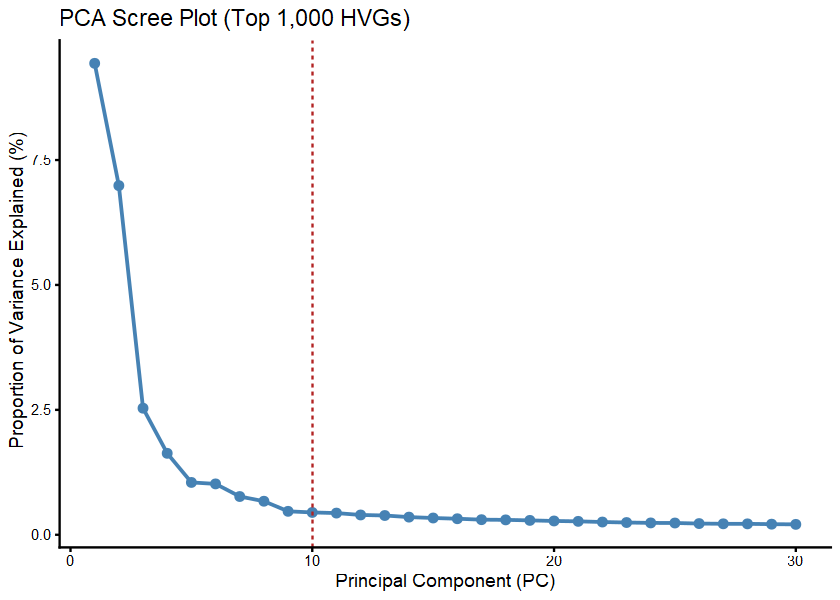

In [24]:
# Extract proportion of variance explained by each principal component
percent_var <- attr(reducedDim(sfe, "PCA"), "percentVar")

# Generate scree diagnostic plot
pca_scree_df <- data.frame(
  PC = seq_along(percent_var), 
  VarianceExplained = percent_var, 
  CumulativeVariance = cumsum(percent_var)
)

# Set canvas dimensions
options(repr.plot.width = 7, repr.plot.height = 5)

p_scree <- ggplot(pca_scree_df, aes(x = PC, y = VarianceExplained)) +
  geom_point(color = "steelblue", size = 2) +
  geom_line(color = "steelblue", linewidth = 0.8) +
  geom_vline(xintercept = 10, linetype = "dashed", color = "firebrick") +
  theme_classic() +
  labs(
    title = "PCA Scree Plot (Top 1,000 HVGs)",
    x = "Principal Component (PC)",
    y = "Proportion of Variance Explained (%)"
  )

p_scree

The scree plot reveals a steep hierarchical drop in variance across the leading components:

* **Dominant Axes (PC1–PC2):** PC1 (≈ 9.4%) and PC2 (≈ 7.0%) account for the largest share of biological variance, reflecting major lineage bifurcations across the tumor–stroma–mucosa axis.
* **Secondary Axes (PC3–PC8):** Explained variance drops sharply to ≈ 2.5% at PC3 and ≈ 1.6% at PC4, before tapering across PC5–PC8 (≈ 0.65%–1.05%) to capture finer cellular subpopulations.
* **Asymptotic Noise Plateau (PC10+):** By **PC9–PC10** (red dashed line), the curve flattens into a horizontal plateau where each subsequent component contributes **< 0.5%** variance, representing stochastic expression noise rather than coherent tissue structure.

Retaining the top **10 PCs** captures the meaningful biological variation while discarding uninformative high-dimensional noise. We now project these top components onto our segmented cell polygons and inspect the gene loadings driving PC1 and PC2.

> Rather than overwriting our 30-PC `"PCA"` slot (which preserves all rotation loadings and explained variance attributes), we retain the full decomposition and simply restrict downstream UMAP and clustering calls to the top 10 informative components (`n_dimred = 10`).

#### Spatial Projection & Gene Loadings

To evaluate whether these unconstrained molecular axes correspond to coherent histological compartments, we project the top four principal components (`PC1`–`PC4`) directly onto the `centroids` using `Voyager::spatialReducedDim()` with a zero-centered diverging color palette (`divergent = TRUE, diverge_center = 0`), visually separating cells at opposite ends of each transcriptional axis. We limit spatial plotting to `PC1`–`PC4` because they capture the dominant macro-anatomical variance, whereas `PC5`–`PC10` (< 1.1% variance each) encode subtle localized cell states that appear faint at full-ROI scale despite remaining essential for multivariate UMAP and clustering.

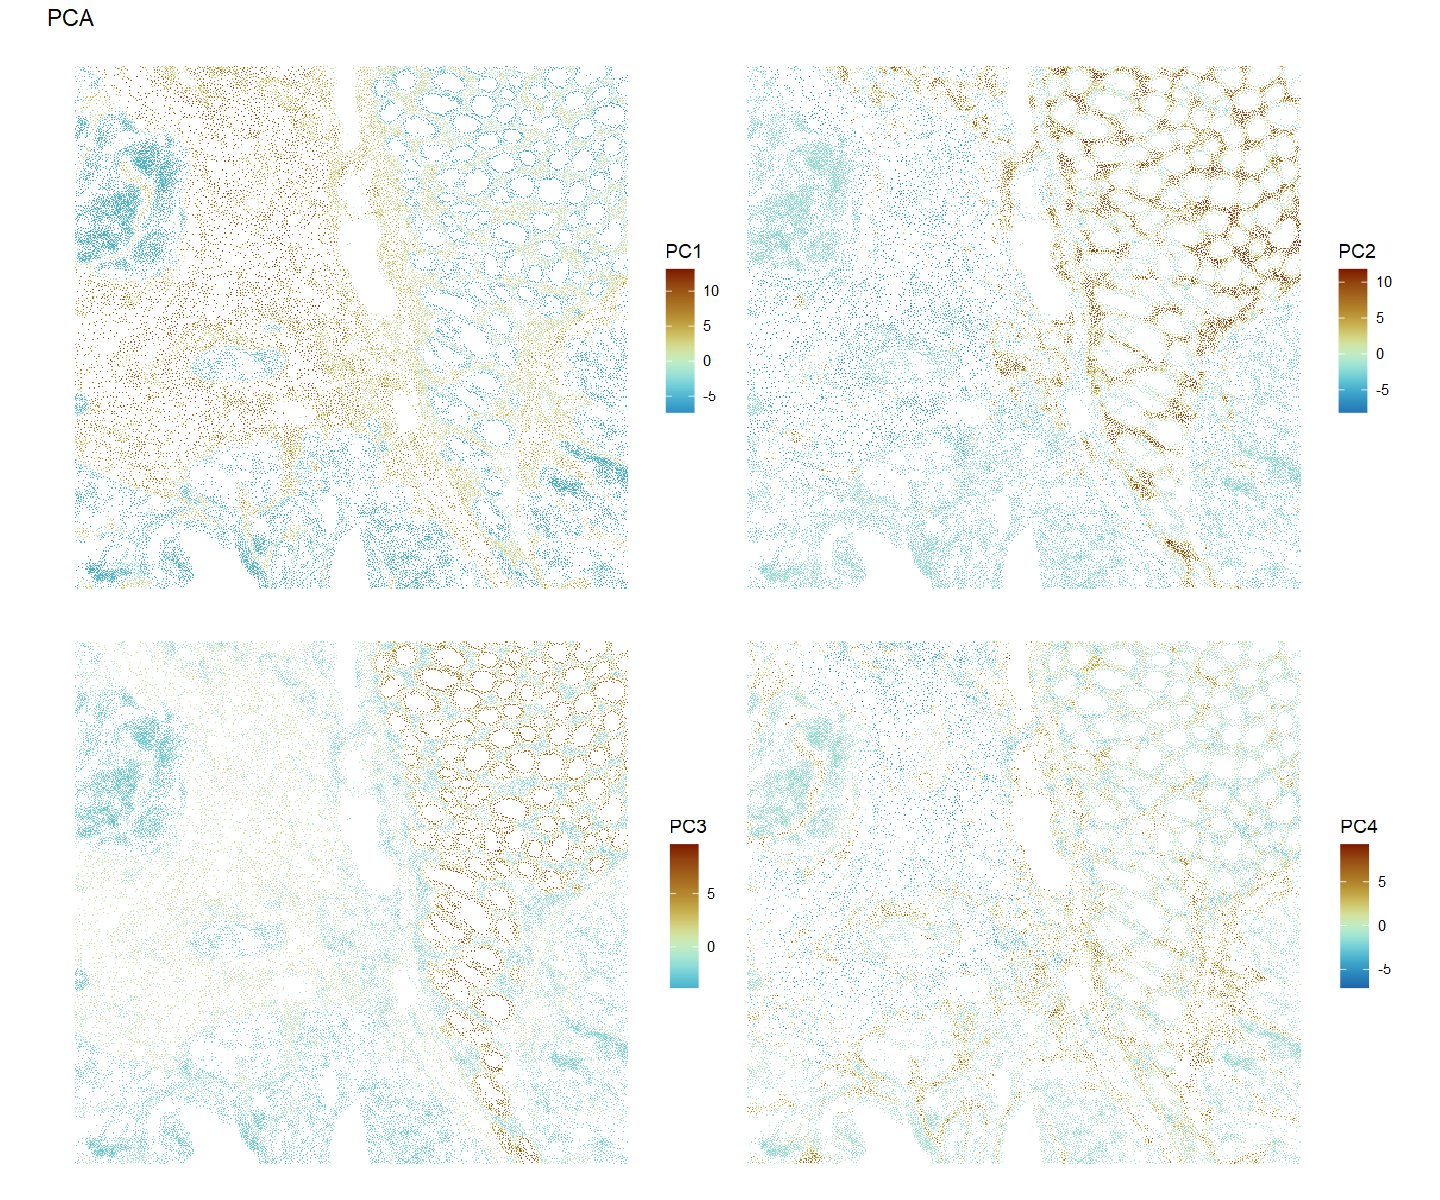

In [25]:
# Project top 4 principal components onto cell centroids
options(repr.plot.width = 12, repr.plot.height = 10)
Voyager::spatialReducedDim(
  sfe, 
  dimred = "PCA", 
  ncomponents = 4, 
  colGeometryName = "centroids", 
  scattermore = TRUE,  # Using scattermore for fast rendering
  divergent = TRUE, 
  diverge_center = 0
)

Despite operating without spatial coordinates, the top four unconstrained principal components segregate the tissue into recognizable anatomical zones (brown = positive scores; cyan/blue = negative scores):

* **`PC1` (Mesenchymal Stroma vs. Epithelium):** Strong positive scores (brown, +5 to +10) blanket the left-hand **desmoplastic stroma**, mirroring the fibrillar collagen (`COL1A1`/`COL3A1`) and `VIM` domains observed earlier. Conversely, negative scores (blue, down to -5) trace the **epithelial compartments**—both the circular normal crypts on the upper right and the neoplastic/submucosal structures along the far-left and lower margins.
* **`PC2` (Mucosal Humoral Immunity vs. Tumor/Stroma):** Positive scores (brown) sharply delineate the **inter-crypt lamina propria honeycomb** in the upper-right normal mucosa and the central invasive immune margin—matching the plasma-cell immunoglobulin network (`IGKC`, `IGHG1`, `JCHAIN`)—while negative scores (blue) span the left-side stroma and tumor bed.
* **`PC3` (Differentiated Crypt Epithelium vs. Invasive Regions):** Positive scores (brown) highlight the **epithelial crypt structures** in the upper right, contrasting against strong negative scores (blue) in the upper-left and lower regions.
* **`PC4` (Finer Microenvironmental Contrast):** With variance explained dropping to ≈ 1.6%, spatial contrast becomes noticeably more diffuse and speckled along the central invasive margin and submucosal patches.

Across all four panels, notice the **grainy, punctate single-cell texture**: because standard PCA evaluates each cell in isolation, stochastic dropout noise causes neighboring cells within the same anatomical zone to fluctuate in intensity—a limitation we will address next using spatially-aware **BANKSY** embeddings.

#### Deconstructing Principal Component Loadings (`PC1` & `PC2`)

In R, the `rotation` attribute stores the $1,000 \times 30$ matrix $V$ of **eigenvectors** (loadings) of the gene–gene covariance matrix. Geometrically, multiplying the centered cell-by-gene matrix $X$ by $V$ rotates the coordinate system from the 1,000 original gene axes onto the new orthogonal Principal Component axes ($Z = X V$). 

Consequently, each cell's spatial PC score is the weighted sum of its centered gene expression multiplied by these eigenvector weights. Ranking the top 10 genes by absolute loading magnitude while preserving their directional sign (`+` vs. `–`) directly reveals which genes push cells toward the brown (`+`) versus cyan/blue (`–`) poles on our spatial PC maps.

In [26]:
# List metadata attached to the reducedDim object
reducedDim(sfe, "PCA") |> attributes() |> names()

[1] "dim"          "dimnames"     "varExplained" "percentVar"   "rotation"

In [27]:
# Extract the gene rotation (loadings) matrix
pca_rot <- attr(reducedDim(sfe, "PCA"), "rotation")

# Filter the top 10 driving genes by loading magnitude for PC1 and PC2
lapply(c("PC1", "PC2"), function(pc) {
  pca_rot[, pc] |> 
    abs() |> 
    sort(decreasing = TRUE) |> 
    names() |> 
    head(n = 10)
}) |> setNames(c("PC1", "PC2"))

$PC1
 [1] "COL3A1"  "COL1A1"  "COL1A2"  "SPARC"   "VIM"     "IGKC"    "CEACAM5"
 [8] "MUC12"   "MMP2"    "TAGLN"  

$PC2
 [1] "IGKC"   "IGHG1"  "JCHAIN" "COL1A1" "IGHM"   "COL3A1" "IGHA1"  "COL1A2"
 [9] "FTH1"   "SPARC"

**`PC1`** is driven primarily by the **non-epithelial** extracellular matrix and **CAF** markers observed among our top HVGs (`COL3A1`, `COL1A1`, `COL1A2`, `SPARC`, `VIM`, `MMP2`, `TAGLN`), paired with **epithelial tumor and mucosal** markers (`CEACAM5`, `MUC12`).

**`PC2`** is rather commanded by five **immunoglobulin** genes (`IGKC`, `IGHG1`, `JCHAIN`, `IGHM`, `IGHA1`) representing the plasma-cell humoral program, balanced against **fibrillar stromal** markers (`COL1A1`, `COL3A1`, `COL1A2`, `SPARC`, `FTH1`).

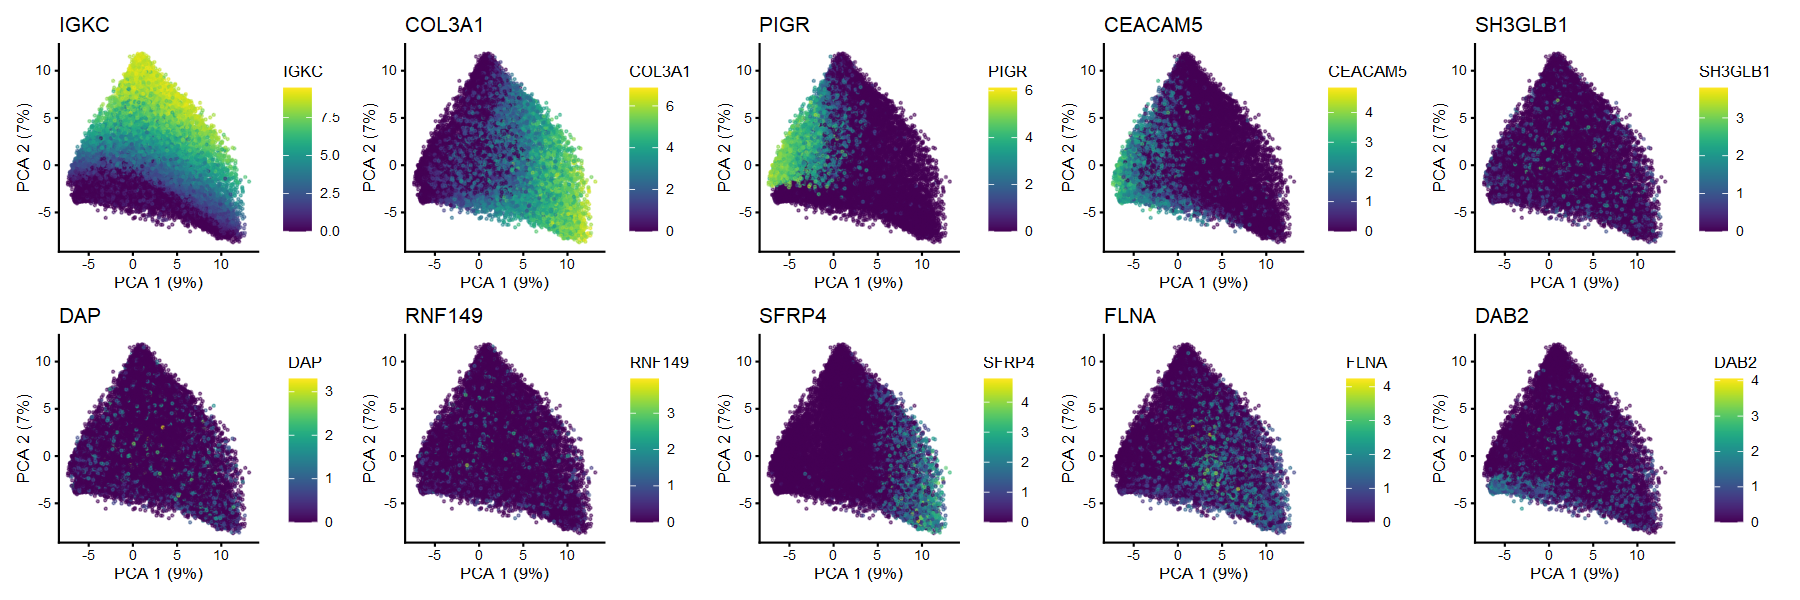

In [28]:
# Generate 2D PCA plots across all 10 benchmark genes without duplicating plot code
pca_plots <- lapply(svg_benchmark_genes, function(gene) {
  scater::plotReducedDim(
    sfe, 
    dimred = "PCA", 
    colour_by = gene, 
    point_size = 0.25, 
    point_alpha = 0.5
  ) +
    # scale_color_gradientn(colors = pals::jet()) +
    labs(title = gene, color = NULL) +
    theme_classic(base_size = 10)
})

# Display in a 2x5 grid
options(repr.plot.width = 15, repr.plot.height = 5)

patchwork::wrap_plots(pca_plots, ncol = 5)

Projecting our 10 benchmark genes onto the `PC1` × `PC2` embedding reveals that the 33,709 cells organize into a **triangular 2-simplex**, where the three vertices correspond to the tissue's fundamental biological archetypes:

1. **The Three Lineage Vertices (`IGKC`, `COL3A1`, `PIGR` / `CEACAM5`):**
   * **Top Apex (`PC1 ≈ 0, PC2 ≈ +11`):** `IGKC` peaks sharply (bright yellow) at the top vertex, isolating humoral plasma cells.
   * **Bottom-Right Vertex (`PC1 ≈ +11, PC2 ≈ -7`):** `COL3A1` forms a continuous gradient into the bottom-right corner, defining the desmoplastic CAF stroma.
   * **Bottom-Left Vertex (`PC1 ≈ -6, PC2 ≈ -3`):** Both `PIGR` (normal mucosal crypts) and `CEACAM5` (invasive adenocarcinoma) converge at the exact same bottom-left epithelial corner. Notice that while `PIGR` and `CEACAM5` are spatially segregated on opposite sides of the tissue slice, `PC1` and `PC2` unite them under a shared epithelial identity—meaning deeper components (`PC3`+) are required to separate normal mucosa from malignant glands.
2. **Specialized Stromal & Architectural SVGs (`SFRP4`, `FLNA`, `DAB2`):**  
   `SFRP4` maps selectively onto the bottom-right `COL3A1` CAF wing (`PC1 > 5`), whereas `FLNA` (smooth muscle) and `DAB2` (submucosal/perivascular bands) occupy the lower baseline (`PC2 < -2`) bridging the stromal and epithelial poles.
3. **Spatially Diffuse HVGs (`SH3GLB1`, `DAP`, `RNF149`):**  
   In stark contrast, all three diffuse HVGs appear as faint, uniform speckles scattered across the entire triangle without enriching any vertex or edge—confirming in reduced-dimension space that their variance is not tied to major cell lineages or tissue domains.

### Spatially-Aware Dimensionality Reduction (BANKSY)

#### Neighborhood Feature Augmentation

Because standard PCA evaluates each cell in isolation, it suffers from two limitations visible in our projections: a grainy single-cell texture driven by technical dropouts, and the tendency of leading PCs to collapse shared cell lineages residing in different tissue compartments (such as `PIGR`+ normal crypts and `CEACAM5`+ tumor nests converging in the same `PC1` × `PC2` vertex).

To embed spatial context directly into dimensionality reduction, we apply **BANKSY** (**B**uilding **A**ggregates with a **N**eighborhood **K**ernel and **S**patial **Y**ardstick). Conceptually, BANKSY unifies the two steps we previously explored separately—building a $k$-nearest neighbor spatial graph and running PCA on our 1,000 HVGs—into a single workflow:

1. **`computeBanksy()`:** Constructs a spatial neighbor graph over cell coordinates (`spatialCoordsNames(sfe)`) and computes each cell's distance-weighted neighborhood expression average across the 1,000 HVGs (`k_geom = 20`).
2. **`runBanksyPCA()`:** Pairs each cell's intrinsic expression with its spatial neighborhood aggregate using a mixing weight (`lambda = 0.8` to emphasize continuous tissue domains over isolated cell typing) and computes PCA on the combined spatio-molecular matrix, returning `PCA_banksy` for spatial mapping and UMAP comparison.

In [29]:
# Define BANKSY parameters
k_geom <- 20
lambda_weight <- 0.8

# Extract spatial coordinate names dynamically from the SFE container
xy_coords <- spatialCoordsNames(sfe)

# Compute BANKSY neighborhood aggregates on the 1,000-HVG slice
set.seed(42)
sfe_banksy <- Banksy::computeBanksy(
  sfe[rowData(sfe)[["is_hvg"]], ], 
  assay_name = "logcounts", 
  coord_names = xy_coords, 
  k_geom = k_geom
)

Computing neighbors...

Spatial mode is kNN_median

Parameters: k_geom=20

Done

Done



In [30]:
# Compute PCA (10 components) on the augmented spatio-molecular matrix
set.seed(42)
sfe_banksy <- Banksy::runBanksyPCA(
  sfe_banksy,
  lambda = lambda_weight,
  npcs = 10
)

# Transfer BANKSY PCs back into our primary SFE container and release temporary object
banksy_slot <- grep("^PCA_", reducedDimNames(sfe_banksy), value = TRUE)[1]
reducedDim(sfe, "PCA_banksy") <- reducedDim(sfe_banksy, banksy_slot)
rm(sfe_banksy)

In [31]:
# Verify all stored dimensionality reduction slots
reducedDimNames(sfe)

[1] "PCA_artifacts" "PCA"           "PCA_banksy"

> **Why Restrict Dimensionality Reduction to 1,000 HVGs Instead of All 18,049 Genes?**  
> 
> Both standard PCA and BANKSY operate exclusively on our 1,000-HVG subset (`is_hvg`) rather than the full 18,049-gene matrix for two reasons:
> 
> 1. **Signal-to-Noise Ratio:** The excluded 17,049 genes are dominated by invariant housekeeping transcripts and low-count Poisson shot noise ($\sigma^2_{\text{bio}} < 0.053$). Although each noisy gene contributes little variance individually, summing 17,000+ uncorrelated noise axes degrades covariance estimation and dilutes Euclidean distances in PCA space.
> 2. **Computational Footprint:** Because BANKSY doubles the feature matrix ($2P$ columns across 33,709 cells), restricting to 1,000 HVGs (2,000 augmented columns) reduces memory overhead by >18× compared to the full transcriptome (36,098 columns). *(Note: Using SVGs instead of HVGs is an alternative when prioritizing strictly spatial gradients, though HVGs provide an unbiased common baseline for comparing non-spatial PCA against BANKSY.)*

#### Spatial Projection & Comparison with Standard PCA

We now project the top four BANKSY principal components (`PC1`–`PC4`) onto cell `centroids` using `Voyager::spatialReducedDim()` to evaluate how neighborhood feature augmentation transforms spatial coherence compared to standard PCA.

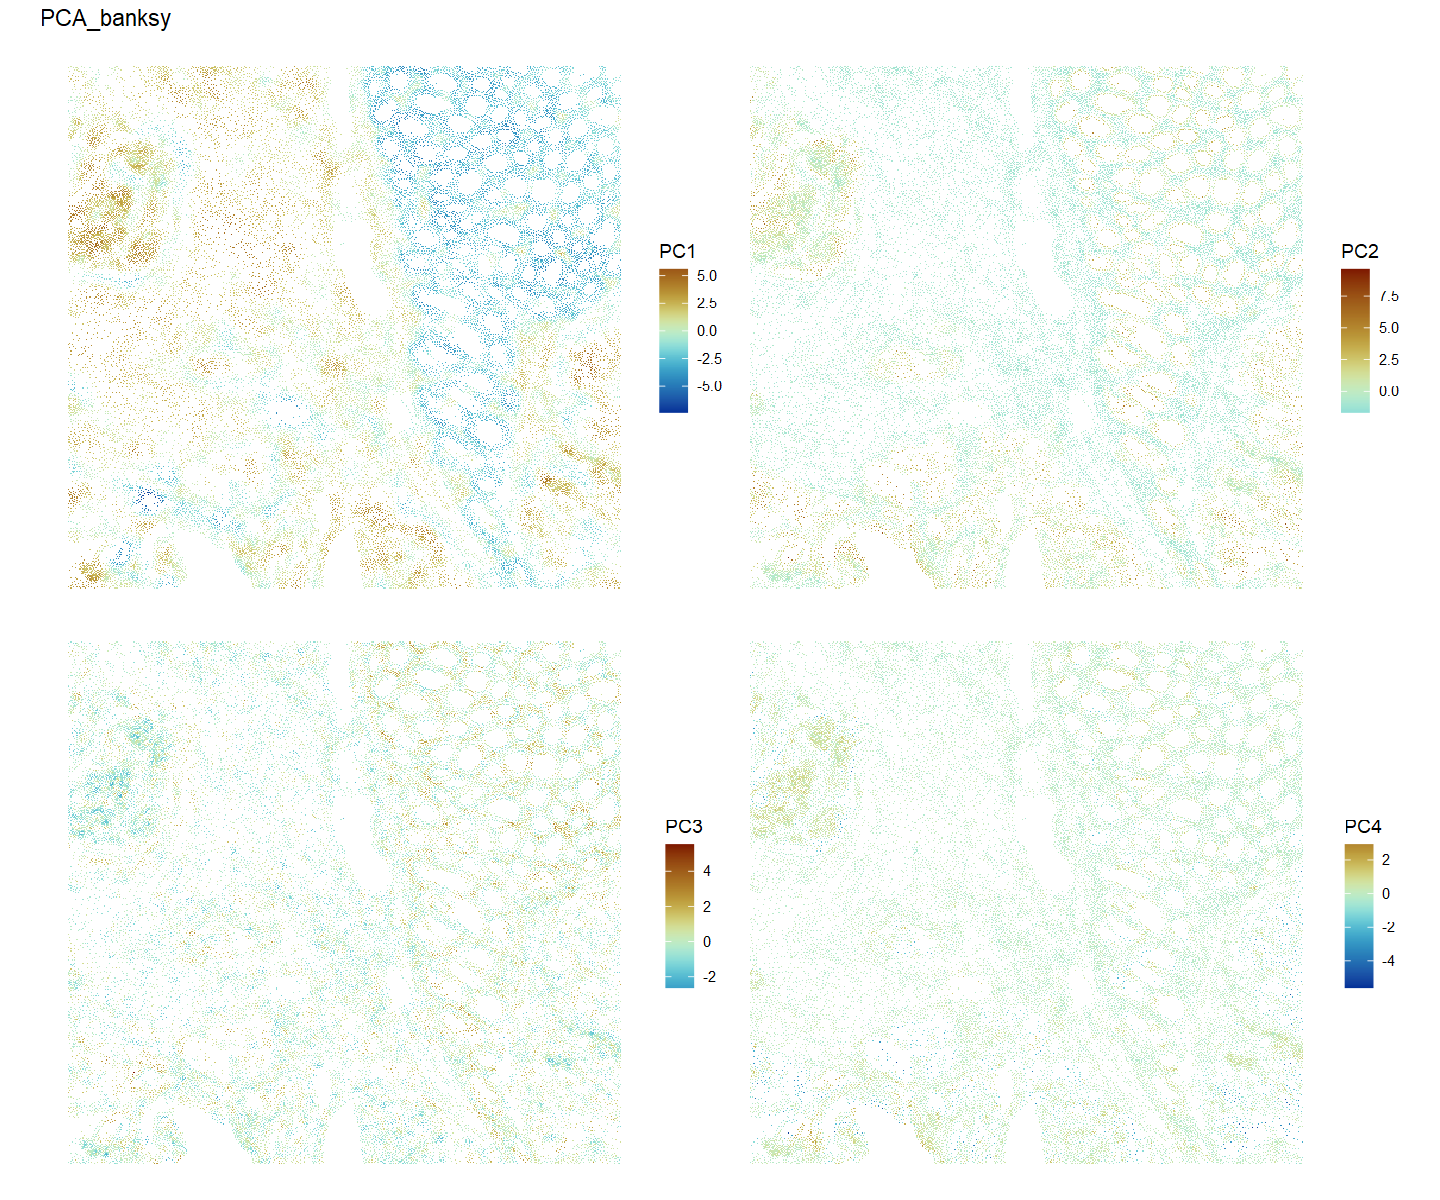

In [32]:
# Project top 4 BANKSY principal components onto cell centroids
options(repr.plot.width = 12, repr.plot.height = 10)
Voyager::spatialReducedDim(
  sfe, 
  dimred = "PCA_banksy", 
  ncomponents = 4, 
  colGeometryName = "centroids", 
  scattermore = TRUE, 
  divergent = TRUE, 
  diverge_center = 0
)

In standard _non-spatially-aware_ `PCA`, `PC1` grouped epithelial structures on *both* sides of the slide (normal right-hand crypts and left-hand tumor/glandular nests) together in cyan/blue based purely on cell-intrinsic expression. In `PCA_banksy`, weighting the $k = 20$ spatial neighborhood ($\lambda = 0.8$) reorganizes `PC1` into a clean **anatomical bifurcation**: the entire **normal colonic mucosa** (upper right, encompassing both crypts and inter-crypt lamina propria) forms a unified cyan/blue domain (`-2.5` to `-5.0`), sharply demarcated from the **invasive adenocarcinoma and desmoplastic stroma bed** on the left and bottom (brown, `+2.5` to `+5.0`). 

Moreover, across `PC1`–`PC4`, neighborhood feature aggregation noticeably dampens the grainy, salt-and-pepper single-cell variability seen in standard `PCA`. Neighboring cells within the same compartment—such as the upper-left submucosal/neoplastic structure highlighted in cyan on `PC3` and olive-brown on `PC4`, or the lower submucosal stromal bands—now share smooth, spatially contiguous scores, providing a noise-resistant foundation for UMAP and domain clustering.

> **How `k_geom` and `lambda` Shape the BANKSY Embedding:**  
> 
> * **Neighborhood Size (`k_geom`):** Decreasing $k$ (e.g., `k_geom = 6–10`) restricts pooling to immediate cell-to-cell contacts (1–2 cell layers), preserving fine vascular or crypt-lining boundaries. Increasing $k$ (e.g., `k_geom = 30–50`) averages across broader 50–100 µm regions, further smoothing dropouts at the cost of blurring sharp tumor–stroma interfaces.
> * **Mixing Weight (`lambda`):** Setting $\lambda = 0$ disables neighborhood aggregation entirely, collapsing BANKSY to standard PCA. Low values ($\lambda \approx 0.2$) support **single-cell typing** by gently denoising dropouts while preserving distinct cell identities (e.g., separating an infiltrating lymphocyte from an adjacent fibroblast). High values ($\lambda \ge 0.7\text{–}0.8$, as used here) prioritize **histological domain discovery**, uniting distinct cell types that co-reside in the same anatomical niche.

#### Eigenvalue Scree Diagnostics (`PCA_banksy`)

Inspecting `PCA_banksy` one component at a time gives the impression that `PC1` carries nearly all the visible contrast, while `PC2`–`PC4` appear comparatively faint across the full tissue slice. Because `Banksy::runBanksyPCA()` strips extra attributes, we compute the component variances (eigenvalues) directly from the 10 orthogonal columns of `reducedDim(sfe, "PCA_banksy")` to quantify how variance is distributed across `PC1`–`PC10`.

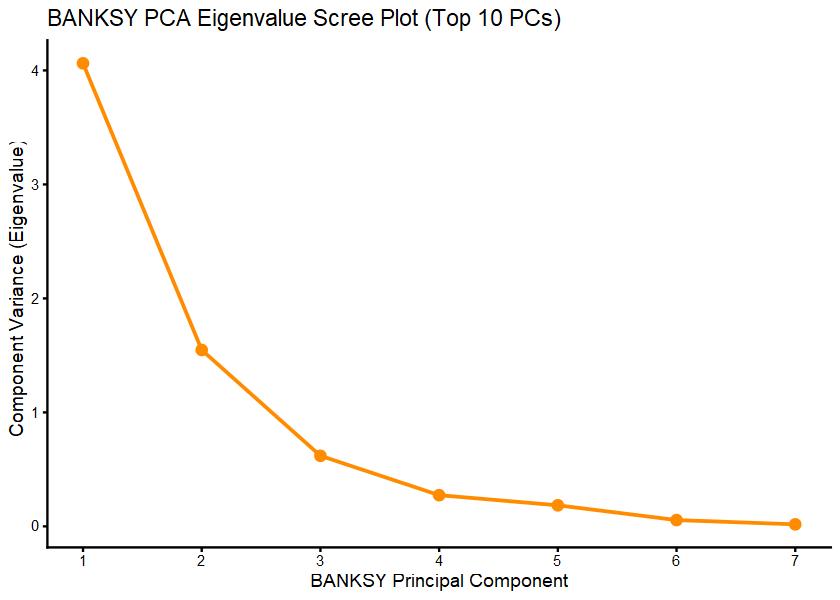

In [33]:
# Compute exact component variance (eigenvalue) for each of the 10 BANKSY PCs.
# We plot raw variance rather than % of total variance because npcs = 10 only computed
# the top 10 eigenvalues rather than the full 2,000-feature eigenspectrum.
banksy_var <- apply(reducedDim(sfe, "PCA_banksy"), 2, var)

# Build scree data frame
banksy_scree_df <- data.frame(
  PC = seq_along(banksy_var), 
  Variance = banksy_var
)

# Plot BANKSY eigenvalue scree curve
options(repr.plot.width = 7, repr.plot.height = 5)

ggplot(banksy_scree_df, aes(x = PC, y = Variance)) +
  geom_point(color = "darkorange", size = 2.5) +
  geom_line(color = "darkorange", linewidth = 0.8) +
  scale_x_continuous(breaks = 1:10) +
  theme_classic() +
  labs(
    title = "BANKSY PCA Eigenvalue Scree Plot (Top 10 PCs)", 
    x = "BANKSY Principal Component", 
    y = "Component Variance (Eigenvalue)"
  )

`PC1` indeed absorbs the steep, dominant macro-domain split (normal mucosa vs. invasive tumor/stroma), while finer sub-compartmental differences (such as submucosal vessels, focal immune nests, and stromal sub-zones) are distributed across `PC2`–`PC10` at lower individual variances.

### Non-Linear Manifold Visualization (UMAP)

**Uniform Manifold Approximation and Projection (UMAP)** resolves this by synthesizing **all 10 principal components simultaneously** into a single non-linear 2D manifold. Computing UMAP on both standard non-spatial PCA (`n_dimred = 10`) and `PCA_banksy` allows us to test whether the combined 10-dimensional BANKSY space resolves sharper, more cohesive biological clusters than standard PCA. Coloring both projections by `detected` gene counts also verifies that technical sequencing complexity does not drive artificial cluster separation.

In [34]:
# Compute UMAP on the top 10 standard PCs
set.seed(42)
sfe <- scater::runUMAP(
  sfe, 
  dimred = "PCA", 
  n_dimred = 10, 
  name = "UMAP"
)

In [35]:
# Compute UMAP on the 10 BANKSY spatial PCs
set.seed(42)
sfe <- scater::runUMAP(
  sfe, 
  dimred = "PCA_banksy", 
  name = "UMAP_banksy"
)

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


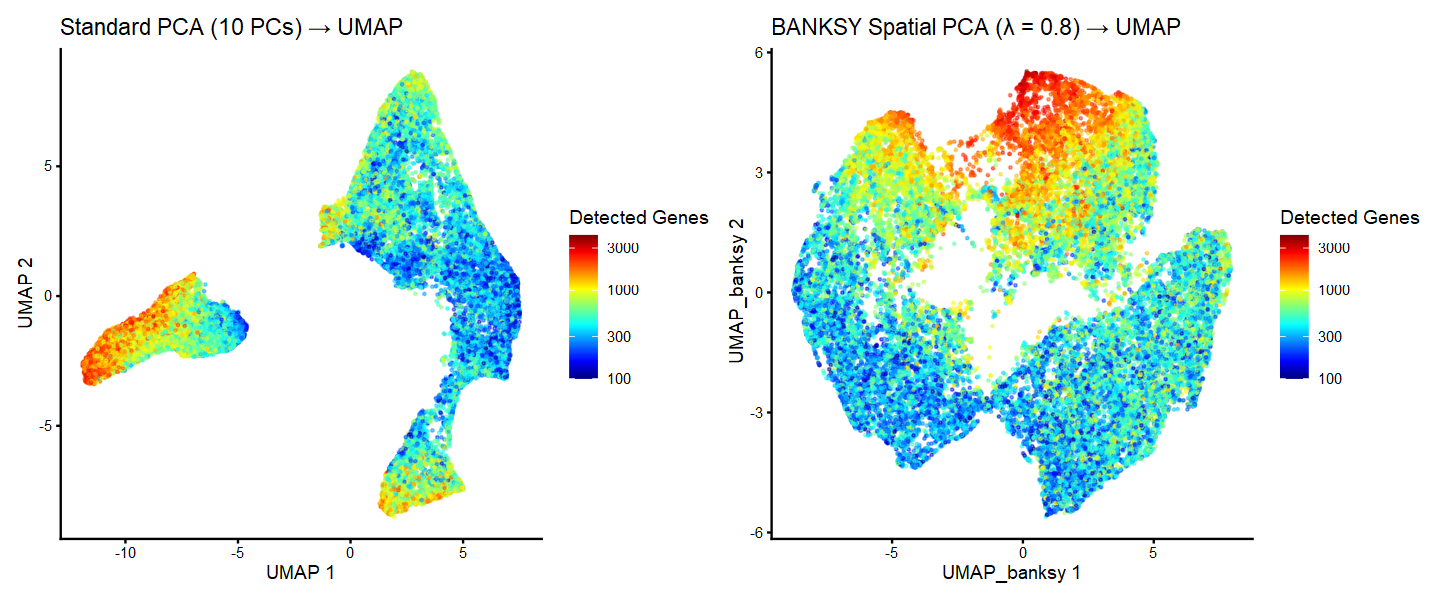

In [36]:
# Visualize both embeddings side-by-side colored by detected genes
options(repr.plot.width = 12, repr.plot.height = 5)

p_umap_std <- scater::plotReducedDim(
  sfe, 
  dimred = "UMAP", 
  colour_by = "detected", 
  point_size = 0.3, 
  point_alpha = 0.5
) +
  scale_color_gradientn(colors = pals::jet(), trans = "log10") +
  labs(title = "Standard PCA (10 PCs) → UMAP", color = "Detected Genes") +
  theme_classic()


p_umap_banksy <- scater::plotReducedDim(
  sfe, 
  dimred = "UMAP_banksy", 
  colour_by = "detected", 
  point_size = 0.3, 
  point_alpha = 0.5
) +
  scale_color_gradientn(colors = pals::jet(), trans = "log10") +
  labs(title = "BANKSY Spatial PCA (λ = 0.8) → UMAP", color = "Detected Genes") +
  theme_classic()

p_umap_std + p_umap_banksy

Driven strictly by cell-intrinsic expression, standard UMAP (Standard PCA → UMAP; left Panel)collapses the tissue into just **two coarse structures**: a small, isolated high-complexity island on the left (`UMAP 1 ∈ [-12, -4]`, 1,000–3,000+ detected genes in orange/red) and a single large, continuous crescent on the right (`UMAP 1 ∈ [-2, +8]`, predominantly 100–1,000 detected genes in blue/cyan, with a small high-count tip at the bottom). Mirroring the three-vertex `PC1` × `PC2` simplex, non-spatial UMAP separates broad cell lineages (epithelium vs. stroma/immune) but merges cells from distinct anatomical regions whenever their intrinsic transcriptomes overlap.

In contrast, synthesizing all 10 BANKSY components (BANKSY Spatial PCA → UMAP; right Panel) unfolds the cells into a **compact multi-lobed, sharply partitioned manifold** separated by clear internal clefts that represent genuine microenvironmental transitions. Rather than trapping all high-UMI epithelial cells in a single isolated island, the top of the BANKSY manifold splits into distinct high-complexity lobes (top-left and top-center/right, orange/red), reflecting epithelial compartments embedded in divergent local neighborhoods (e.g., normal mucosal crypts vs. invasive adenocarcinoma nests). Similarly, the lower-count stromal and immune populations (blue/cyan/green, bottom half) separate into distinct left and right sub-lobes rather than merging into one elongated continuum.

In both projections, `detected` gene counts exhibit a smooth biological gradient from quiescent stroma (100–300 genes, blue) to transcriptionally active glandular epithelium (1,000–3,000+ genes, orange/red)—consistent with the size-factor compartments established in Module 07—without fracturing into artificial low-count technical debris clusters.

## Finalization

We serialize the enriched `SpatialFeatureExperiment` object—containing our biological variance annotations (`is_hvg`, `bio`), spatial statistics (`moran_sample01`, `LR_stat`, `prop_sv`, `padj`), and reduced-dimension embeddings (`PCA`, `PCA_banksy`, `UMAP`, `UMAP_banksy`)—to disk via `alabaster.sfe::saveObject()` for downstream spatial clustering in the next notebooks.

In [37]:
# Check the structure of the final SFE object
sfe

class: SpatialFeatureExperiment 
dim: 18049 33709 
metadata(1): Samples
assays(2): counts logcounts
rownames(18049): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(11): ID Symbol ... prop_sv padj
colnames(33709): 80404 80411 ... 189331 189341
colData names(36): Sample Barcode ... sizeFactor_smooth sf_ratio
reducedDimNames(5): PCA_artifacts PCA PCA_banksy UMAP UMAP_banksy
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: col: knn6

In [38]:
# Define standardized output directory
output_dir <- "output/sfe_visiumhd_segmented_dimred"

# Replace existing directory cleanly if present
if (dir.exists(output_dir)) {
  unlink(output_dir, recursive = TRUE)
}

# Serialize enriched SFE object
alabaster.sfe::saveObject(sfe, output_dir)

# Verify directory creation
fs::dir_tree(output_dir)

>>> Saving SpatialExperiment

>>> Saving colgeometries

>>> Saving spatial graphs



output/sfe_visiumhd_segmented_dimred
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   ├── 1
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   ├── OBJECT
│   └── other_columns
│       └── 26
│           ├── array.h5
│           └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── images
│   ├── 0
│   │   ├── image.tiff
│   │   └── OBJECT
│   ├── 1
│   │   ├── image.tiff
│   │   └── OBJECT
│   └── mapping.h5
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── reduced_dimensions
│   ├── 0
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz
│   │   │   └── OBJECT
│   │   └── OBJECT
│   ├── 1
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz
│ 

Finally, we clear the workspace and trigger garbage collection to release high-dimensional intermediate matrices from memory before opening the downstream clustering module.

In [39]:
rm(list = ls())
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,13595498,726.1,21377650,1141.7,21377650,1141.7
Vcells,30155180,230.1,103049813,786.3,741198982,5654.9
